# 03 — Evaluation and error analysis

All numbers come from `reports/tables/` (written by `python -m src.evaluate`); the figures are in `reports/figures/`. Each result has a short interpretation under it.

**Goals set before modelling:** G1, test MAE ≥ 15% below persistence; G2, Poor+ recall ≥ 0.80 with precision ≥ 0.60.

In [1]:
import json, sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # so `src` imports work from notebooks/

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src.config import FEATURE_FILE, FIGURES, MODELS, TABLES, SEED, POOR_THRESHOLD
from src.features import FEATURES, NEXT_WEATHER_FEATURES, NUMERIC_FEATURES

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160, "display.max_columns", 30)
mae = lambda a, b: float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
feats = pd.read_csv(FEATURE_FILE, parse_dates=["Date", "target_date"])
print(feats.shape)
preds = pd.read_csv(TABLES / "predictions.csv", parse_dates=["Date", "target_date"])
summary = json.loads((TABLES / "summary.json").read_text())
show = lambda name, w=800: display(Image(filename=str(FIGURES / f"{name}.png"), width=w))

(24816, 48)


## 1. Why these metrics
* **MAE** (µg/m³): readable, and the unit the goal is stated in.
* **RMSE**: punishes large misses, i.e. the spikes that matter most for health.
* **Poor+ flag**: precision, recall, F1 and PR-AUC. Not accuracy: in 2020 only 8.6% of days are Poor+, so "never warn" would score 91% accuracy and be useless.

## 2. Regression: all models, validation and test

,split,model,MAE,RMSE,MAE on Poor+ days,MAE gain vs persistence %,gain 95% CI
0,val,Persistence (baseline),13.72,27.13,32.23,0.00,NaN
1,val,Seasonal mean (baseline),28.03,42.60,44.80,-104.35,NaN
2,val,Ridge,13.21,25.09,29.74,3.72,"[2.0, 5.4]"
3,val,Random forest,13.08,25.15,29.70,4.62,"[3.0, 6.1]"
4,val,LightGBM,12.42,24.28,29.68,9.47,"[7.7, 11.2]"
5,test,Persistence (baseline),10.26,17.37,28.02,0.00,NaN
6,test,Seasonal mean (baseline),33.52,42.21,43.09,-226.66,NaN
7,test,Ridge,9.99,15.95,24.63,2.61,"[0.2, 4.8]"
8,test,Random forest,9.80,15.67,24.95,4.53,"[2.8, 6.2]"
9,test,LightGBM,9.23,14.99,24.74,10.01,"[8.2, 11.7]"


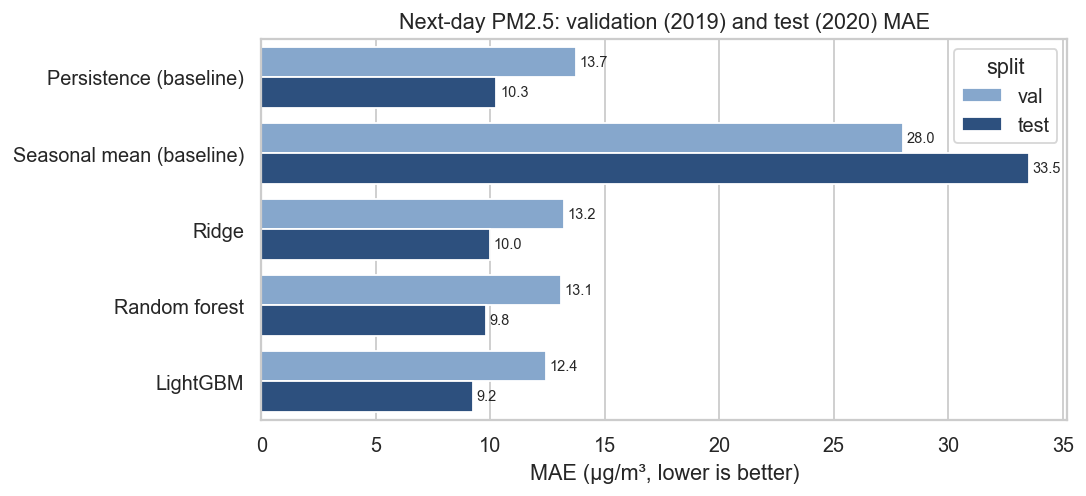

In [2]:
reg = pd.read_csv(TABLES / "regression_results.csv")
display(reg)
show("model_comparison", 700)

**Interpretation.** LightGBM is best on both 2019 and 2020 (test MAE 9.23 vs 10.26 for persistence, RMSE 15.0 vs 17.4). The bootstrap CI over days, [8.2%, 11.7%], excludes zero, so the gain is real, but it also excludes 15%: **G1 is not met.** Ridge and the forest beat persistence only slightly; most of the edge comes from non-linear interactions (rain, season, recent change) that LightGBM captures. The seasonal mean is more than 3× worse than persistence.

## 3. Which inputs matter? Ablation and permutation importance

,features,val_MAE,val_gain_vs_persistence_%,test_MAE,test_gain_vs_persistence_%
0,pollution + calendar (no weather),12.86,6.3,9.54,7.1
1,+ today's weather (main model),12.42,9.5,9.23,10.0
2,"+ tomorrow's actual weather (oracle forecast, ...",11.89,13.3,8.84,13.8


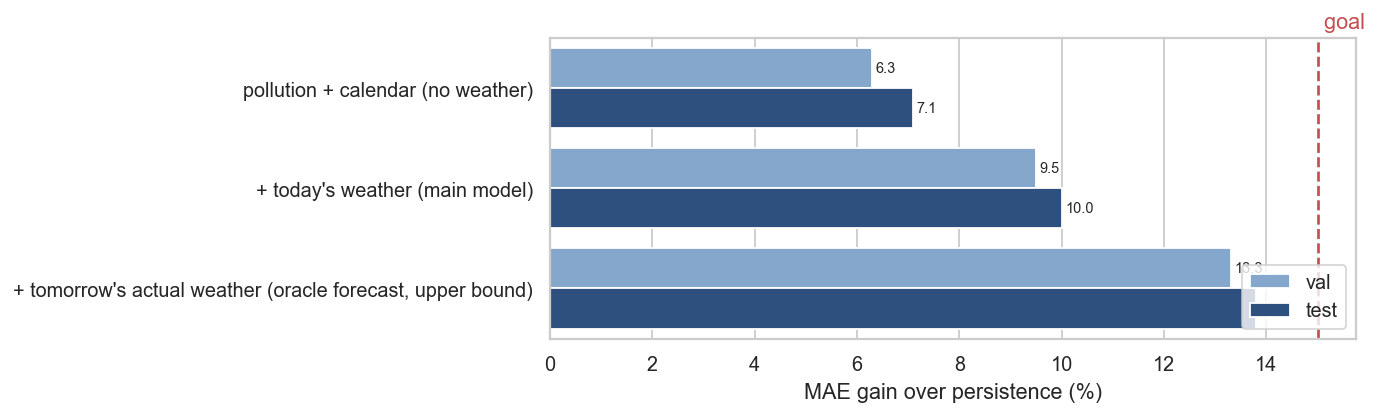

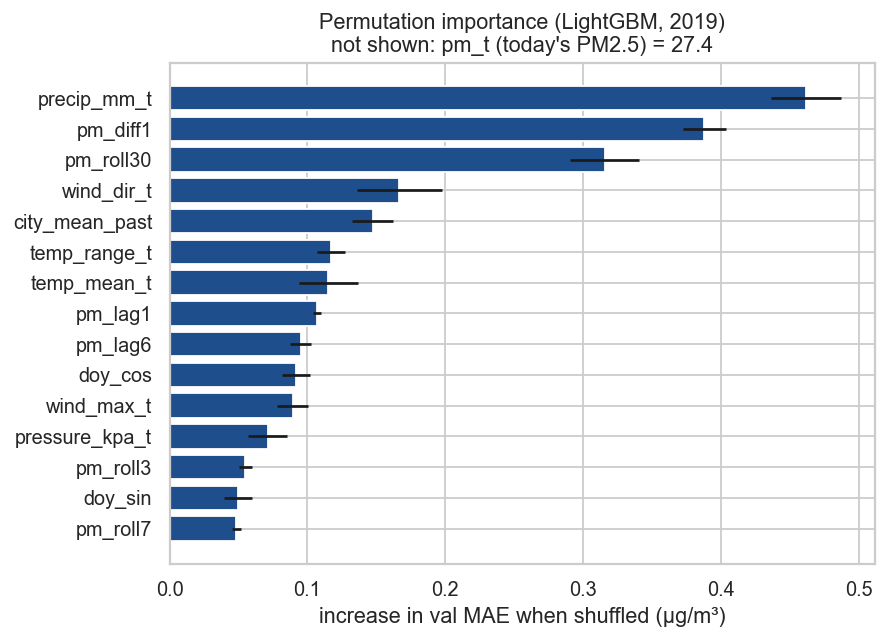

In [3]:
display(pd.read_csv(TABLES / "ablation_features.csv"))
show("ablation_features", 750)
show("permutation_importance", 520)

**Interpretation.** History and calendar alone give ~7%; today's weather adds ~3 points (rain is the single most useful weather variable: it washes particles out). Even the *oracle*, tomorrow's actual weather, reaches only 13.8%, so 15% is unlikely with daily city averages. The missing information is local emissions and smoke transport, not model capacity.

## 4. Classification: Poor+ days

,split,model,threshold,precision,recall,F1,PR-AUC,Poor+ rate
0,val,Persistence rule (today > 90),90.000,0.788,0.787,0.787,0.858,0.169
1,val,Logistic regression,0.558,0.773,0.799,0.786,0.870,0.169
2,val,LightGBM classifier,0.699,0.810,0.799,0.805,0.888,0.169
3,val,LightGBM regressor + threshold,88.503,0.810,0.799,0.805,0.885,0.169
4,test,Persistence rule (today > 90),90.000,0.713,0.735,0.724,0.783,0.086
5,test,Logistic regression,0.558,0.691,0.790,0.737,0.815,0.086
6,test,LightGBM classifier,0.699,0.733,0.771,0.752,0.829,0.086
7,test,LightGBM regressor + threshold,88.503,0.742,0.748,0.745,0.831,0.086


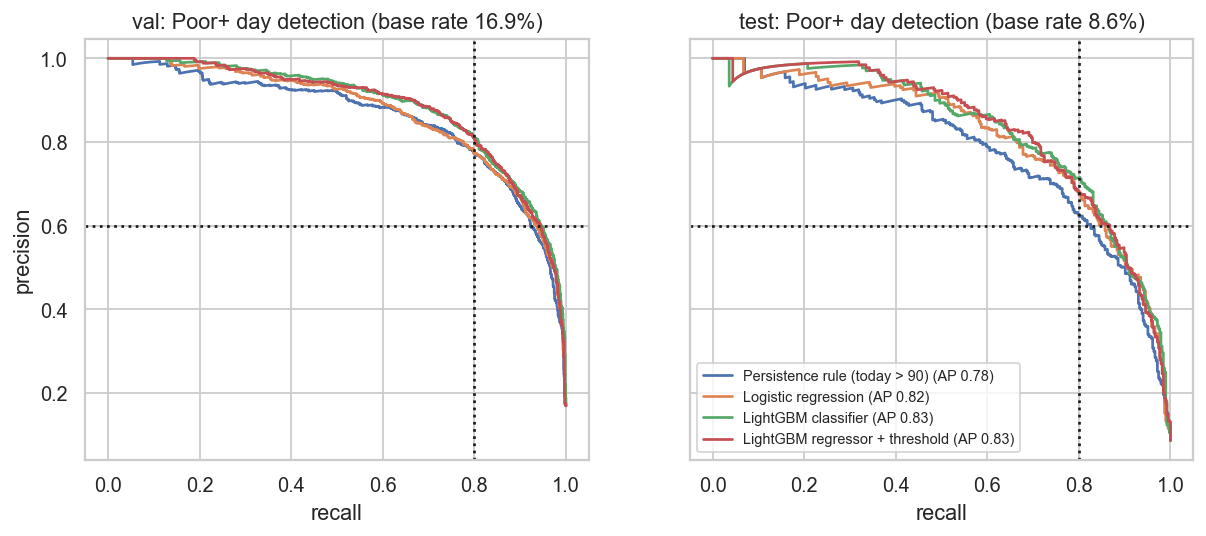

{'best_classifier_by_val': 'LightGBM regressor + threshold', 'test_recall': 0.748, 'test_precision': 0.742}


In [4]:
clf = pd.read_csv(TABLES / "classification_results.csv")
display(clf)
show("pr_curves", 850)
print({k: summary[k] for k in ["best_classifier_by_val", "test_recall", "test_precision"]})

**Interpretation.** Thresholds were set on 2019 to give recall 0.80. On 2020 recall drops to ~0.75 for the chosen model while precision stays ~0.74: **G2 is narrowly missed.** The cause is the base-rate shift (16.9% → 8.6% Poor+), not a broken model: the test PR curve still passes through recall 0.80 at precision ≈ 0.72, and all ML classifiers beat the persistence rule in PR-AUC (0.83 vs 0.78). A threshold recalibrated on recent data would fix most of the gap.

## 5. Error analysis
### 5.1 Over time, by season, and the lockdown

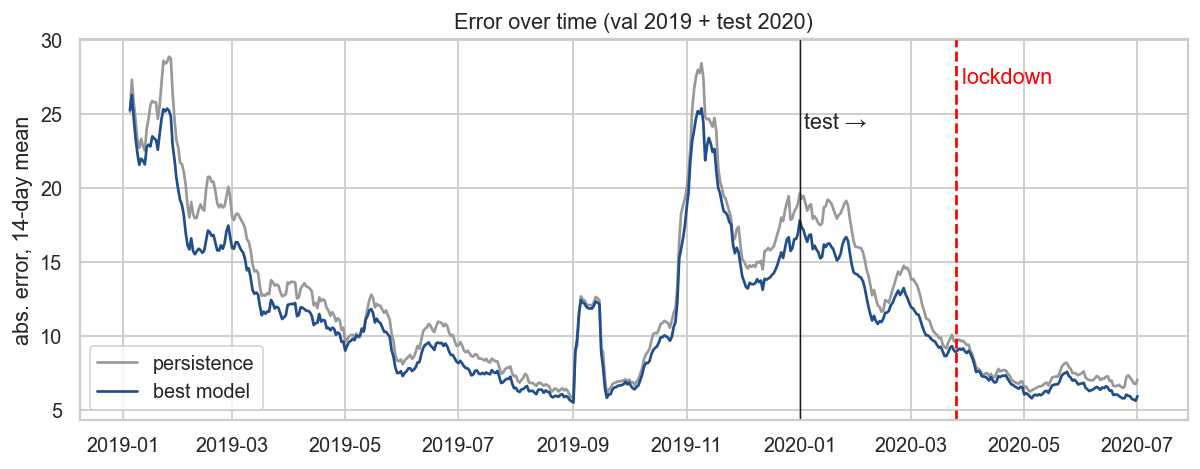

,split,season,model,persistence,n,mean_pm25
0,test,monsoon,6.15,7.06,747,24.38
1,test,summer,7.48,7.97,2273,33.35
2,test,winter,13.59,15.52,1444,70.32
3,val,monsoon,7.72,8.37,2326,30.93
4,val,post_monsoon,15.90,17.28,1339,71.09
5,val,summer,10.75,11.86,1677,54.28
6,val,winter,17.53,19.81,1773,90.71


,MAE model,MAE persistence,mean PM2.5,Poor+ rate
2020 before lockdown,12.39,13.97,62.5,0.176
2020 lockdown onwards,6.61,7.18,28.2,0.012


In [5]:
show("residuals_over_time", 850)
display(pd.read_csv(TABLES / "error_by_season.csv"))
pd.DataFrame(summary["lockdown"]).T

**Interpretation.** Error tracks pollution level: it is largest in winter and post-monsoon and smallest in the monsoon. The model's line stays under persistence almost everywhere. Across the 25 March 2020 lockdown, mean PM2.5 halves and Poor+ days nearly vanish (17.6% → 1.2%), yet the model keeps its ~10% edge (12.4 vs 14.0 before; 6.6 vs 7.2 after). Predicting the *change* from today makes it robust to this level shift.

### 5.2 By city: who gets the worst forecasts?

,City,model,persistence,n,mean_pm25,seen_in_training,beats_persistence
25,Talcher,16.98,18.15,155,68.59,True,True
24,Delhi,16.56,19.75,183,80.32,True,True
23,Guwahati,15.66,17.26,182,74.00,False,True
22,Brajrajnagar,14.88,18.88,138,64.78,True,True
21,Lucknow,14.76,17.70,183,76.87,True,True
20,Gurugram,14.44,16.44,183,67.02,True,True
19,Patna,12.72,13.78,183,61.32,True,True
18,Jorapokhar,11.33,12.05,144,56.96,False,True


Model beats persistence in 25 of 26 cities
Unseen-city MAE 7.94 | seen-city MAE 9.85


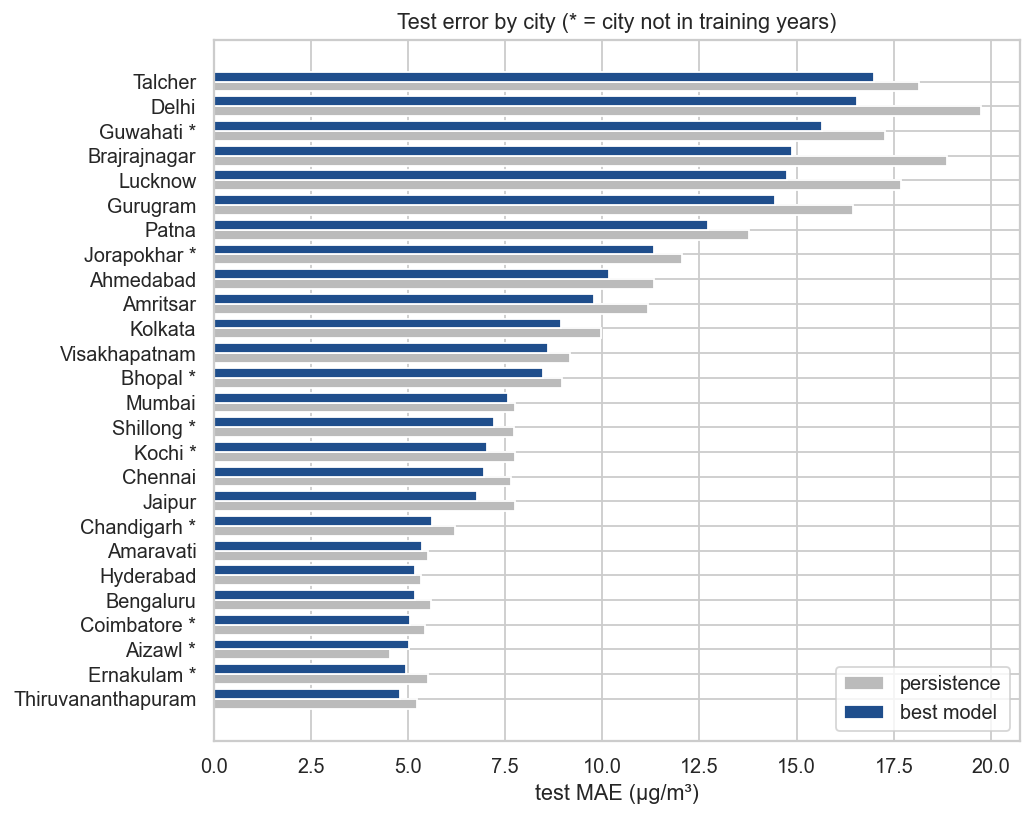

In [6]:
by_city = pd.read_csv(TABLES / "error_by_city_test.csv").sort_values("model", ascending=False)
by_city["beats_persistence"] = by_city.model < by_city.persistence
display(by_city.head(8))
print(f"Model beats persistence in {by_city.beats_persistence.sum()} of {len(by_city)} cities")
print("Unseen-city MAE", summary["test_MAE_cities_new_in_2019_20"], "| seen-city MAE", summary["test_MAE_cities_seen_in_training"])
show("error_by_city_test", 560)

**Interpretation (bias).** The largest errors are in the most polluted places, including small industrial towns (Talcher, Brajrajnagar) as well as Delhi. A single national MAE hides this, and those residents get the least reliable warnings. Cities never seen in training do *better* (7.9) only because most are clean hill or coastal cities. The one city where persistence wins, Aizawl, has very low PM2.5 and only 110 test days.

### 5.3 Size of the misses

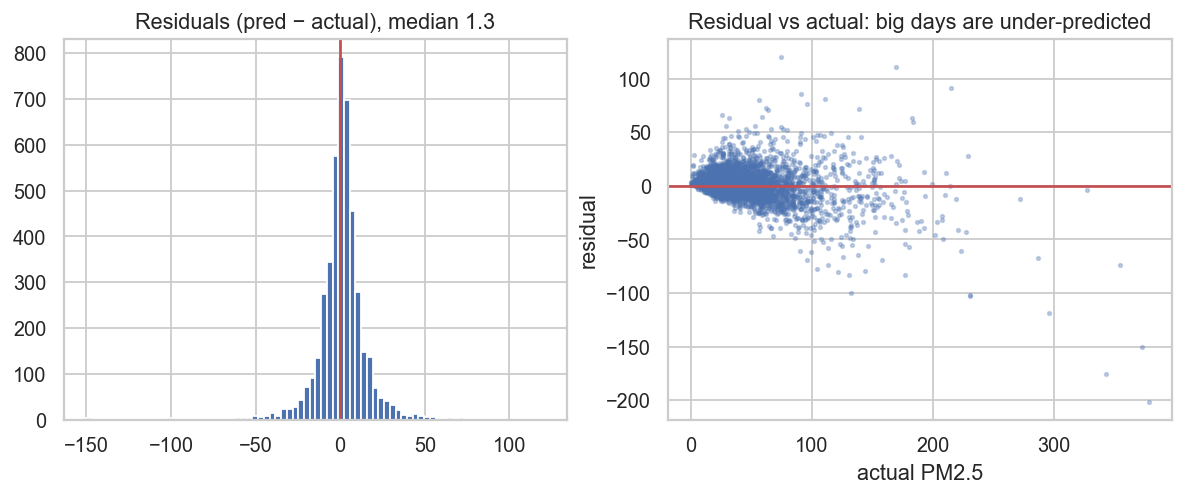

median residual 1.27 | mean residual on Poor+ days -10.28


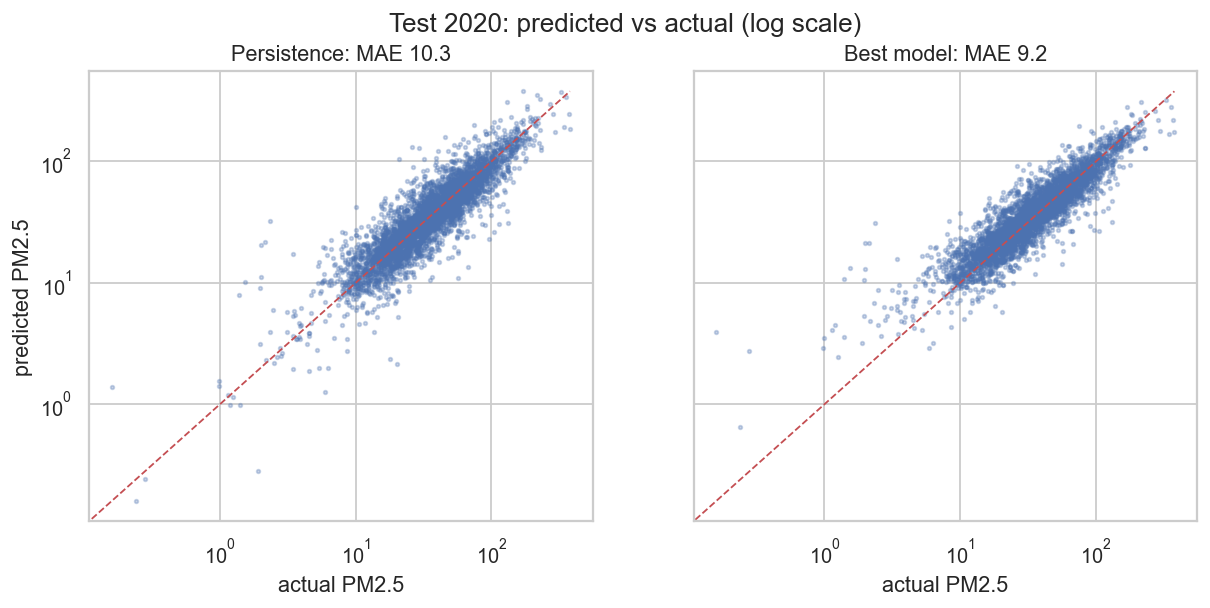

In [7]:
show("residuals_distribution_test", 850)
print("median residual", summary["test_median_residual"], "| mean residual on Poor+ days", summary["test_mean_residual_on_Poor+_days"])
show("pred_vs_actual_test", 850)

**Interpretation.** Residuals are centred (median +1.3), but on Poor+ days the model under-predicts by ~10 µg/m³ on average: it is conservative about big jumps, so it shrinks towards persistence. That is the right behaviour when a jump can't be seen coming, but it is the main source of missed warnings.

### 5.4 The 20 worst forecasts

In [8]:
worst = pd.read_csv(TABLES / "worst20_test.csv", parse_dates=["target_date"])
worst["jump"] = (worst.y - worst.today).round(1)
display(worst)
print("in January:", (worst.target_date.dt.month == 1).sum(), "| Talcher:", (worst.City == "Talcher").sum())

,City,target_date,today,y,prediction,abs_error,jump
0,Guwahati,2020-01-15,186.6,378.1,176.1,202.0,191.5
1,Talcher,2020-01-24,192.2,342.4,167.0,175.4,150.2
2,Delhi,2020-01-01,245.5,372.1,221.4,150.7,126.6
3,Delhi,2020-01-23,198.9,74.4,195.2,120.7,-124.5
4,Gurugram,2020-01-01,175.7,296.1,177.5,118.5,120.4
5,Guwahati,2020-01-16,378.1,169.6,280.3,110.7,-208.5
6,Talcher,2020-01-07,131.0,230.8,128.2,102.5,99.8
7,Talcher,2020-01-22,124.5,230.2,128.6,101.6,105.7
8,Ahmedabad,2020-06-02,31.0,131.9,31.6,100.3,100.9
9,Talcher,2020-01-26,354.4,214.8,306.5,91.7,-139.6


in January: 14 | Talcher: 6


**Interpretation.** 14 of the 20 worst forecasts fall in January, the peak season, and nearly all are one-day jumps or drops of 80–200 µg/m³ (e.g. Guwahati on 15 Jan: 187 → 378). The model predicted roughly "today", like persistence. Talcher, a coal-mining town, appears 6 times. These look like local events (fires, mining, burning) that leave no trace in yesterday's city average or the weather, which motivates adding fire counts and upwind-city data.

### 5.5 Diwali

In [9]:
pd.Series(summary["val_2019_diwali_window"])

n                  109.00
MAE model           25.40
MAE persistence     30.23
dtype: float64

**Interpretation.** In the ±2-day Diwali window of 2019 the model beats persistence (25.4 vs 30.2) thanks to the Diwali flag, but the errors are still about twice the yearly average. Festival smoke is only partly predictable from the calendar.

### 5.6 Delhi, test year

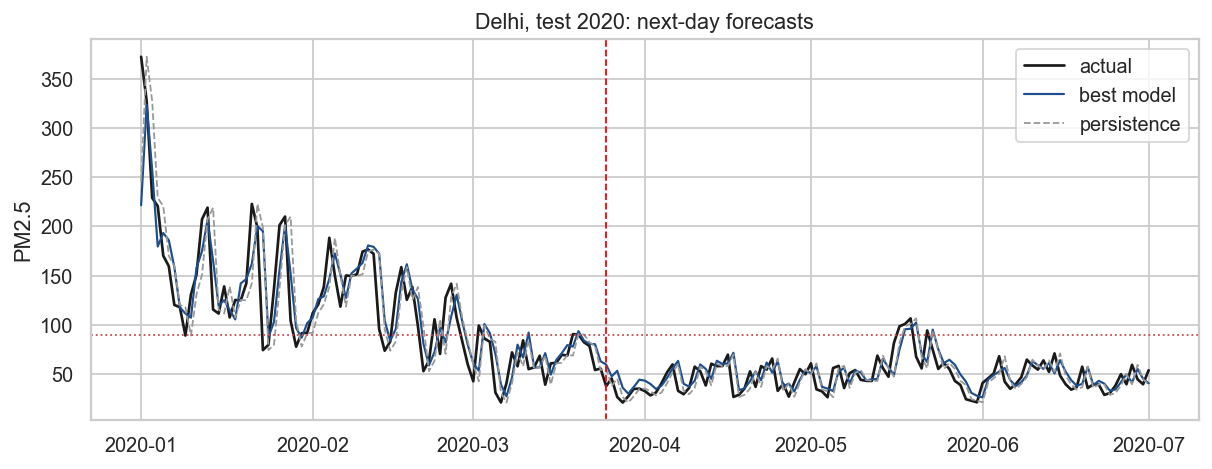

In [10]:
show("delhi_test_timeseries", 850)

## 6. Goals: final check

In [11]:
pd.Series({k: v for k, v in summary.items() if k in [
    "best_regressor_by_val", "test_MAE_gain_vs_persistence_%", "test_gain_95CI", "goal1_met (>= 15%)",
    "best_classifier_by_val", "test_recall", "test_precision", "goal2_met (recall>=0.80 & precision>=0.60)"]})

best_regressor_by_val                                               LightGBM
test_MAE_gain_vs_persistence_%                                         10.01
test_gain_95CI                                                   [8.2, 11.7]
goal1_met (>= 15%)                                                     False
best_classifier_by_val                        LightGBM regressor + threshold
test_recall                                                            0.748
test_precision                                                         0.742
goal2_met (recall>=0.80 & precision>=0.60)                             False
dtype: object

## 7. Conclusions, limitations and next steps
* The model gives a **reliable 10% improvement** over persistence (CI 8–12%), consistent across CV, 2019, 2020, 25 of 26 cities and the lockdown. Neither pre-set goal is fully met, and both misses are explained: missing inputs (G1) and base-rate shift (G2).
* **Limitations:** daily city averages; coarse reanalysis weather standing in for forecasts; a short, atypical test half-year; structurally missing pollutants.
* **Bias:** training data is dominated by big northern and metro cities; small polluted towns have the largest errors; a national threshold ignores local vulnerability.
* **Next steps:** real weather forecasts plus boundary-layer height; fire counts and upwind PM2.5; a rolling recalibration of the Poor+ threshold; quantile forecasts to give uncertainty; per-city error reporting.